# 4. The NASA almond
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sap6/MFS/blob/main/notebooks/4_almond.ipynb)

The NASA almond is a familiar test case in computational electromagnetics (Section 6 of the paper). Every cross-section is a 3:1 ellipse, so the continued field is singular near a *focal curve* in the mid-plane, within 6% of the rim, and at the sharp tip this curve reaches the surface. The sources are electric and magnetic dipoles on the mid-plane, in rows that approach the focal curve, and each row is continued towards the tip by a tail with the exponents of the tip cone (`mfs/almond.py`).

In [1]:
# On Colab: get the code and the data (this cell does nothing when run locally)
import os, sys
if "google.colab" in sys.modules and not os.path.exists("MFS"):
    !git clone -q https://github.com/sap6/MFS
    !pip install -q -e MFS
    os.chdir("MFS/notebooks")

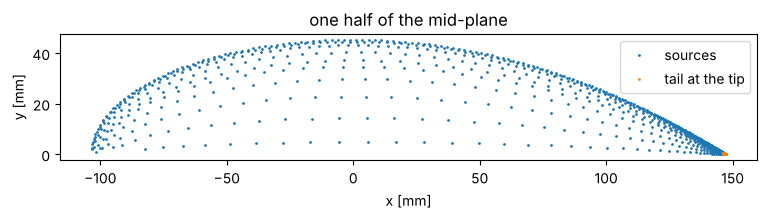

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mfs import almond, core

y = almond.source_rows(6, 3)               # the layout 6:3: six rows in the middle, four towards the focal curve
tail = almond.tip_tail(6, 3)[0]
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.plot(y[:, 0] * 1e3, y[:, 1] * 1e3, ".", ms=2, label="sources")
ax.plot(tail[:, 0] * 1e3, tail[:, 1] * 1e3, ".", ms=2, label="tail at the tip")
ax.set(aspect="equal", xlabel="x [mm]", ylabel="y [mm]", title="one half of the mid-plane")
ax.legend()
plt.show()

## Convergence at 1.19 GHz
The wave meets the tip first (nose-on), polarised along $y$; the almond is one wavelength long. Each layout is measured against the finest one, 8:5.

In [3]:
k = 2 * np.pi * 1.19e9 / almond.C0
pts = 0.3 * core.fibonacci(400)
E_ref = almond.nose_on(k, 8, 5, pts)[2]
for n_mid, n_F in ((3, 0), (4, 1), (5, 2), (6, 3)):
    y, c, E, (ext, sca), shape = almond.nose_on(k, n_mid, n_F, pts)
    print(f"layout {n_mid}:{n_F}, {shape[1]} unknowns: difference {core.rel(E, E_ref):.1e}, optical mismatch {abs(ext - sca) / sca:.1e}")

layout 3:0, 795 unknowns: difference 6.7e-02, optical mismatch 1.4e-01


layout 4:1, 1377 unknowns: difference 4.0e-03, optical mismatch 8.1e-03


layout 5:2, 2103 unknowns: difference 2.8e-04, optical mismatch 3.4e-04


layout 6:3, 2937 unknowns: difference 5.6e-05, optical mismatch 7.6e-05


## Radar cross-section against the Austin benchmark
The monostatic radar cross-section at 3.5 GHz, in the plane of the almond, against the reference simulation and the measurements of the Austin RCS Benchmark Suite (Kelley et al. 2020; data in `data/austin_almond`). One factorisation per parity class serves all look angles.

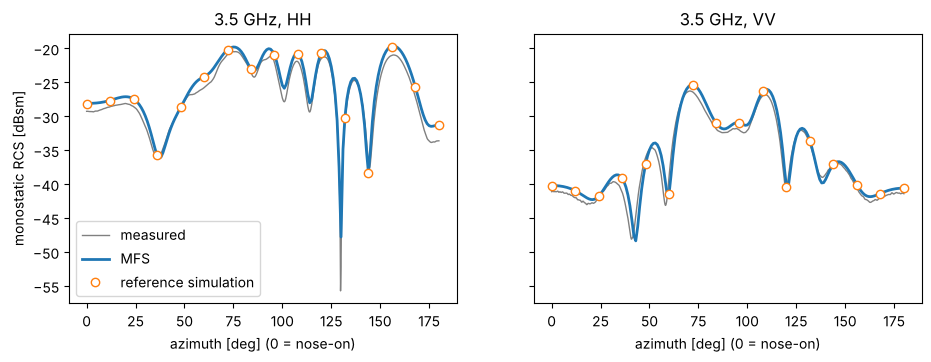

In [4]:
out = almond.rcs(3.5, step=1.0)            # about a minute

def austin(kind, pol):
    d = np.loadtxt(f"../data/austin_almond/{kind}_rcs.III.A.s1.fx1.{pol[0]}.txt")
    return d[:, 2], d[:, 3]

fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, pol in zip(axs, ("HH", "VV")):
    ax.plot(*austin("meas.m1", pol), color="grey", lw=1, label="measured")
    ax.plot(out["phi_deg"], 10 * np.log10(out["sigma_" + pol]), lw=2, label="MFS")
    phi, ref = austin("ref", pol)
    ax.plot(phi[::24], ref[::24], "o", mfc="white", label="reference simulation")
    ax.set(xlabel="azimuth [deg] (0 = nose-on)", title=f"3.5 GHz, {pol}")
axs[0].set_ylabel("monostatic RCS [dBsm]")
axs[0].legend()
plt.show()